# 01 · From Pretrained to Aligned: RLHF, DPO and GRPO

This is a module of Neural Networks 1002. It assumes [module 10 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/10-gpt-from-scratch/) (the GPT built from scratch, next-token prediction, sampling) and [module 04 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/04-reinforcement-learning/) (reinforcement learning: policy gradient, baselines, PPO, reward hacking).

A **base model** only predicts the next token. It imitates its training text, mistakes included. Turning it into something that *does the task* is called **post-training**, and this notebook runs the whole pipeline at toy scale on a laptop CPU:

1. a tiny GPT is pre-trained on text in which the answers to a sorting task are right only a quarter of the time (like noisy web text);
2. **supervised fine-tuning (SFT)** on a few correct demonstrations;
3. a **reward model** (RM) trained from pairwise preferences with the Bradley-Terry loss, and measured against the ground truth;
4. **policy-gradient fine-tuning** with a penalty for drifting away from the SFT model: REINFORCE (REward Increment = Nonnegative Factor x Offset Reinforcement x Characteristic Eligibility) and a PPO (proximal policy optimisation) clipped update, while measuring true accuracy, reward and KL (Kullback-Leibler divergence);
5. **reward over-optimisation**: push the proxy reward too far and the true quality collapses (Goodhart's law), with the KL coefficient as the knob;
6. **DPO** (direct preference optimisation) on the same preference pairs;
7. **GRPO** (group relative policy optimisation) with a verifiable reward, no reward model and no value network;
8. limits, how the toy differs from production systems, and a note on alignment, safety and evaluation.

**Contents**
1. The toy task and the base model
2. SFT: learning from demonstrations
3. A reward model from preferences
4. Policy gradient against the reward model, with a KL penalty
5. Reward over-optimisation (Goodhart's law)
6. DPO: preferences without a reward model
7. GRPO: verifiable rewards, no value network
8. Comparison, limits, alignment and evaluation
9. Key takeaways, Exercises, References

**Builds on**

| Module | What it gave us | Used here |
|---|---|---|
| 1001 module 10, LLMs (GPT from scratch) | the decoder-only GPT, next-token loss, sampling | the model class, pre-training, sampling in section 1 |
| 1001 module 04, reinforcement learning | policy gradient, baselines, PPO clipping, reward hacking | sections 4, 5 and 7 |
| 1001 module 03, training well | AdamW, gradient clipping, learning rates | every training loop |

**Next:** [module 14 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/14-agents-and-orchestration/) (agents and orchestration, where the same reward ideas steer tool-using systems; see also the [RAG systems course](https://rag-systems.academy.forwardforecasting.eu/05-agents-with-langgraph/) for agents with LangGraph) and [module 15](https://neural-networks-1002.academy.forwardforecasting.eu/15-generalist-models-and-agi/) (generalist models and the road to AGI (artificial general intelligence), where verifiable-reward training is part of how reasoning models are built).

Where the toy differs from real systems: our model has about 100 thousand weights and answers are 6 tokens long; production models have billions of weights, answers of hundreds of tokens, reward models of similar size and human or AI (artificial intelligence) labellers. The mechanisms are the same, the numbers are not comparable.

Time: about 2 minutes in a clean 2-CPU environment (measured; it took up to 15 minutes, 939 s, on a busy shared laptop); the over-optimisation runs in section 5 take about a third of it.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/01_rlhf_and_alignment.ipynb)

**Running in Google Colab?** Choose *Runtime > Run all*. The first code cell installs only what is missing (no session restart needed). **Measured run time** in a clean 2-CPU environment like Colab's: about 2 minutes, with a peak memory of under 1 GB (model and data downloads were done on a fast connection). A free Colab CPU is usually slower than the machine used for the measurement, so allow more time; the timings printed in the saved outputs come from a multi-core machine.

In [ ]:
# Setup: works locally and in Google Colab. Installs only the packages that are missing.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'torch': 'torch',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Installing:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('WARNING: the pip install failed; continuing. Details:\n' + _r.stderr[-400:])
print(f"Environment: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import copy, math, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

T_START = time.time()
random.seed(0); np.random.seed(0); torch.manual_seed(0)
torch.set_num_threads(2)

## 1. The toy task and the base model

We need a task with a **checkable ground truth**, so that every claim about quality can be measured and not just argued. We use **sorting five digits**: the prompt `s41846=` should be followed by `14468` and a newline. One token is one character, and the model is the GPT of module 10 of Neural Networks 1001, made smaller (2 layers, width 64, about 100 thousand weights) so that everything runs in minutes.

The key design choice: the pre-training text contains answers that are **right only 25 % of the time**. The other 75 % are plausible mistakes: one digit changed, two neighbours swapped, or a full shuffle. A base model trained on this learns the *distribution of answers in the text*, wrong ones included, exactly as a model trained on web text learns to imitate whatever is there. Two ways to read the model out will behave very differently:

* **greedy decoding** (always the most likely token) returns the mode of the distribution;
* **sampling at temperature 1** returns a draw from the distribution, so its accuracy is the fraction of probability mass that sits on correct answers.

Post-training mostly acts on the second quantity: it moves probability mass onto good answers. All accuracies below are **sampled** and **exact match** (all six tokens right), measured on fixed held-out prompts unless said otherwise. With 600 to 1000 prompts, a measured accuracy has a noise of about plus or minus 2 points.

In [2]:
N = 5                                           # digits per prompt
chars = list("0123456789s=\n")
stoi = {c: i for i, c in enumerate(chars)}      # digit characters have ids 0..9, equal to their value
itos = {i: c for c, i in stoi.items()}
V = len(chars)
enc = lambda s: [stoi[c] for c in s]
dec = lambda ids: "".join(itos[i] for i in ids)
LL = N + 2 + N + 1                              # line length: 's' + 5 digits + '=' + 5 digits + newline = 13 tokens

def corrupt(sorted_digits):
    # a plausible mistake: change one digit, swap two neighbours, or shuffle everything
    a = list(sorted_digits); k = random.random()
    if k < 0.4:
        a[random.randrange(N)] = random.randint(0, 9)
    elif k < 0.7:
        i = random.randrange(N - 1); a[i], a[i + 1] = a[i + 1], a[i]
    else:
        random.shuffle(a)
    return a

def make_line(p_good):
    # one training line: prompt, '=', answer. The answer is correct with probability p_good.
    ds = [random.randint(0, 9) for _ in range(N)]
    ans = sorted(ds) if random.random() < p_good else corrupt(sorted(ds))
    return "s" + "".join(map(str, ds)) + "=" + "".join(map(str, ans)) + "\n"

def make_prompts(n):
    ds = torch.randint(0, 10, (n, N))
    prompts = torch.cat([torch.full((n, 1), stoi["s"]), ds, torch.full((n, 1), stoi["="])], 1)
    return ds, prompts

def truth(ds, seq):
    # ground truth: exact match with the sorted digits plus the newline, and the fraction of right characters
    ans = seq[:, N + 2:]
    gold = torch.cat([ds.sort(1).values, torch.full((len(ds), 1), stoi["\n"])], 1)
    return (ans == gold).all(1).float(), (ans == gold).float().mean(1)

print("examples of corpus lines (the answer after '=' is sometimes wrong, like noisy web text):")
for _ in range(6): print("  ", repr(make_line(0.25)))

examples of corpus lines (the answer after '=' is sometimes wrong, like noisy web text):
   's66048=80466\n'
   's82421=12248\n'
   's24115=11645\n'
   's93877=87789\n'
   's16097=51679\n'
   's39332=32339\n'


In [3]:
class Attn(nn.Module):
    def __init__(s, d, h):
        super().__init__(); s.h = h; s.qkv = nn.Linear(d, 3 * d); s.proj = nn.Linear(d, d)
    def forward(s, x):
        B, T, D = x.shape; q, k, v = s.qkv(x).split(D, 2)
        q, k, v = (t.view(B, T, s.h, D // s.h).transpose(1, 2) for t in (q, k, v))
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)      # causal mask: each token sees only the past
        return s.proj(y.transpose(1, 2).reshape(B, T, D))

class Block(nn.Module):
    def __init__(s, d, h):
        super().__init__(); s.l1 = nn.LayerNorm(d); s.a = Attn(d, h); s.l2 = nn.LayerNorm(d)
        s.m = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def forward(s, x):
        x = x + s.a(s.l1(x)); return x + s.m(s.l2(x))

class GPT(nn.Module):
    # the GPT of module 10 of Neural Networks 1001, without the KV cache, smaller: 2 layers, width 64
    def __init__(s, V, block=16, d=64, L=2, h=4):
        super().__init__(); s.te = nn.Embedding(V, d); s.pe = nn.Embedding(block, d)
        s.blocks = nn.ModuleList(Block(d, h) for _ in range(L)); s.lnf = nn.LayerNorm(d)
        s.head = nn.Linear(d, V, bias=False); s.head.weight = s.te.weight; s.apply(s._i)
    def _i(s, m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, 0, 0.02)
        if isinstance(m, nn.Linear) and m.bias is not None: nn.init.zeros_(m.bias)
    def hidden(s, idx):
        x = s.te(idx) + s.pe(torch.arange(idx.shape[1]))
        for b in s.blocks: x = b(x)
        return s.lnf(x)
    def forward(s, idx): return s.head(s.hidden(idx))

def lm_loss(m, batch, answer_only=False):
    x, y = batch[:, :-1], batch[:, 1:]
    lo = F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1), reduction="none").view(y.shape)
    return (lo[:, N + 1:] if answer_only else lo).mean()

@torch.no_grad()
def sample(m, prompts, greedy=False):
    # write the 6 answer tokens (5 digits and the newline), one token at a time
    idx = prompts
    for _ in range(N + 1):
        lg = m(idx)[:, -1]
        nx = lg.argmax(-1, keepdim=True) if greedy else torch.multinomial(lg.softmax(-1), 1)
        idx = torch.cat([idx, nx], 1)
    return idx

torch.manual_seed(1); EV_DS, EV_P = make_prompts(1000)      # a fixed evaluation set of 1000 prompts
def evaluate(m, greedy=False):
    seq = sample(m, EV_P, greedy); return truth(EV_DS, seq)[0].mean().item()

torch.manual_seed(0); random.seed(0)
model = GPT(V)
print(f"GPT with {sum(p.numel() for p in model.parameters()):,} parameters")

GPT with 101,952 parameters


## 2. Pre-training and SFT

First the base model: next-token loss over 20,000 lines, 500 AdamW steps. Then **SFT** (supervised fine-tuning): continue training with the same next-token loss, but only on **200 demonstrations that are always correct**, and with the loss on the answer tokens only. SFT is "imitate good examples", the first stage of every assistant pipeline. We then freeze a copy of the SFT model as the **reference policy** $\pi_{\text{ref}}$ (pi, the probability the reference model gives to a sequence), which every later stage uses to measure how far the new model has moved.

In [4]:
random.seed(0); torch.manual_seed(0)
data = torch.tensor(enc("".join(make_line(0.25) for _ in range(20000)))).view(-1, LL)
STEPS = 500
opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.1, betas=(0.9, 0.95))
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, total_steps=STEPS, pct_start=0.05)
t0 = time.time()
for step in range(STEPS):
    loss = lm_loss(model, data[torch.randint(len(data), (64,))])
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
base = model
acc_base_s, acc_base_g = evaluate(base), evaluate(base, greedy=True)
print(f"pre-training: {STEPS} steps, {time.time() - t0:.0f} s, final loss {loss.item():.3f}")
print(f"base model, sampling at temperature 1: {acc_base_s:.1%} of the answers are exactly right")
print(f"base model, greedy decoding         : {acc_base_g:.1%}")
ds, p = make_prompts(6); sq = sample(base, p)
for d, q in zip(ds, sq): print("  ", "".join(map(str, d.tolist())), "->", dec(q[N + 2:].tolist()).strip())

pre-training: 500 steps, 118 s, final loss 1.326
base model, sampling at temperature 1: 36.7% of the answers are exactly right
base model, greedy decoding         : 99.5%


   73539 -> 33579
   57894 -> 45789
   57557 -> 55577
   65577 -> 56577
   03548 -> 03458
   26971 -> 16979


In [5]:
# Supervised fine-tuning (SFT): 200 demonstrations that are always correct, loss only on the answer tokens
random.seed(5); torch.manual_seed(5)
sft_data = torch.tensor(enc("".join(make_line(1.0) for _ in range(200)))).view(-1, LL)
sm = copy.deepcopy(base)
o = torch.optim.AdamW(sm.parameters(), lr=2e-4)
for step in range(40):
    loss = lm_loss(sm, sft_data[torch.randint(len(sft_data), (32,))], answer_only=True)
    o.zero_grad(); loss.backward(); o.step()
acc_sft_s, acc_sft_g = evaluate(sm), evaluate(sm, greedy=True)
print(f"after SFT (40 steps on 200 demonstrations): sampled {acc_sft_s:.1%}, greedy {acc_sft_g:.1%}")

ref = copy.deepcopy(sm).eval()          # frozen reference policy for every KL penalty below
for q in ref.parameters(): q.requires_grad_(False)

after SFT (40 steps on 200 demonstrations): sampled 76.1%, greedy 99.6%


**Reading.** Greedy decoding of the base model is already right 99.5 % of the time: the single most likely answer is the correct one, because correct answers are the most frequent single pattern. But sampling gives only 36.7 % exact answers, because the mass is spread over many plausible mistakes. This gap is the situation of a real base model: the right behaviour exists in it, but not reliably. 40 SFT steps on 200 correct demonstrations lift the sampled accuracy to 76.1 % while greedy stays at 99.6 %. SFT is cheap and effective, and it leaves 24 % of sampled answers wrong, which is the room the next stages work on. (Real SFT sets are far more diverse and the gain is also about format and style, not only accuracy.)

## 3. A reward model from preferences

Demonstrations tell the model what to write. **Preferences** tell it which of two outputs is better, which is easier for people to give than a perfect answer. A **reward model** $r_\phi(x, y)$ (a scalar score for prompt $x$ and answer $y$; $\phi$ are its weights) is trained so that the preferred answer $y_w$ ("winner") scores higher than the rejected $y_l$ ("loser") with the **Bradley-Terry** model: the probability that $y_w$ wins is $\sigma(r_\phi(x,y_w) - r_\phi(x,y_l))$, where $\sigma$ is the logistic function. The loss is

$$\mathcal{L}(\phi) = -\,\mathbb{E}\,\log \sigma\big(r_\phi(x,y_w) - r_\phi(x,y_l)\big).$$

Only score **differences** within a prompt are identified, a point that matters in section 4.

Our preference data is generated by a **rule**: a correct answer beats a wrong one. This lets us measure the reward model against the truth, which is impossible with human labels. To make it realistic, the rejected answers are samples from the model, half of them replaced by **near misses** (a sorted answer with one digit changed, which looks right but is not), and **10 % of the labels are flipped** to mimic annotator noise. The reward model is the SFT network with a scalar head on the average hidden state of the answer positions.

In [6]:
def near_miss(ds):
    # a hard negative: a sorted answer in which one digit was replaced by another value (so it LOOKS sorted but is wrong)
    a = ds.sort(1).values.clone(); n = len(a)
    pos = torch.randint(0, N, (n,)); a[torch.arange(n), pos] = (a[torch.arange(n), pos] + torch.randint(1, 10, (n,))) % 10
    return a.sort(1).values

def make_pairs(n, seed, flip=0.0, hard=0.0, policy=None):
    # n prompts -> (chosen, rejected) pairs. The rule (ground truth) says: a correct answer beats a wrong one.
    # The wrong answers are sampled from the model (a fraction `hard` are near-misses); `flip` is label noise.
    torch.manual_seed(seed); ds, p = make_prompts(n)
    a = sample(policy or base, p)
    nl = torch.full((n, 1), stoi["\n"])
    gold = torch.cat([p, ds.sort(1).values, nl], 1)
    nm = torch.cat([p, near_miss(ds), nl], 1)
    a = torch.where((torch.rand(n) < hard)[:, None], nm, a)
    keep = truth(ds, a)[0] == 0                  # keep only prompts where the sampled answer is wrong
    w, l = gold[keep], a[keep]
    f = torch.rand(len(w)) < flip
    return torch.where(f[:, None], l, w), torch.where(f[:, None], w, l)

class RM(nn.Module):
    # reward model: the SFT network with a scalar head on the average hidden state of the answer positions
    def __init__(s, backbone):
        super().__init__(); s.g = copy.deepcopy(backbone); s.v = nn.Linear(64, 1)
    def forward(s, seq): return s.v(s.g.hidden(seq)[:, N + 1:].mean(1)).squeeze(-1)

W, L = make_pairs(12000, 10, flip=0.10, hard=0.5)          # training pairs, 10 % of the labels flipped
teW, teL = make_pairs(3000, 11, hard=0.5)                  # held-out pairs with clean labels
onW, onL = make_pairs(6000, 12, policy=sm)                 # held-out pairs whose wrong answers come from the SFT policy
print(f"{len(W)} training pairs; example chosen/rejected: {dec(W[0][N + 2:].tolist()).strip()!r} > {dec(L[0][N + 2:].tolist()).strip()!r} "
      f"(prompt {dec(W[0][1:N + 1].tolist())})")

torch.manual_seed(0)
rm = RM(sm); o = torch.optim.AdamW(rm.parameters(), lr=5e-4, weight_decay=0.01)
t0 = time.time(); rm_losses = []
for step in range(300):
    i = torch.randint(len(W), (32,))
    loss = -F.logsigmoid(rm(W[i]) - rm(L[i])).mean()          # Bradley-Terry loss
    o.zero_grad(); loss.backward(); o.step(); rm_losses.append(loss.item())
with torch.no_grad():
    acc_rm_mixed = (rm(teW) > rm(teL)).float().mean().item()
    acc_rm_on = (rm(onW) > rm(onL)).float().mean().item()
    ds_, p_ = make_prompts(2000); S = sample(sm, p_); r = rm(S); MU, SD = r.mean().item(), r.std().item()
print(f"reward model trained in {time.time() - t0:.0f} s")
print(f"held-out pair accuracy (clean labels), mixed wrong answers: {acc_rm_mixed:.1%}")
print(f"held-out pair accuracy, wrong answers sampled from the SFT policy: {acc_rm_on:.1%}")

9869 training pairs; example chosen/rejected: '12557' > '81572' (prompt 57215)


reward model trained in 100 s
held-out pair accuracy (clean labels), mixed wrong answers: 95.1%
held-out pair accuracy, wrong answers sampled from the SFT policy: 94.4%


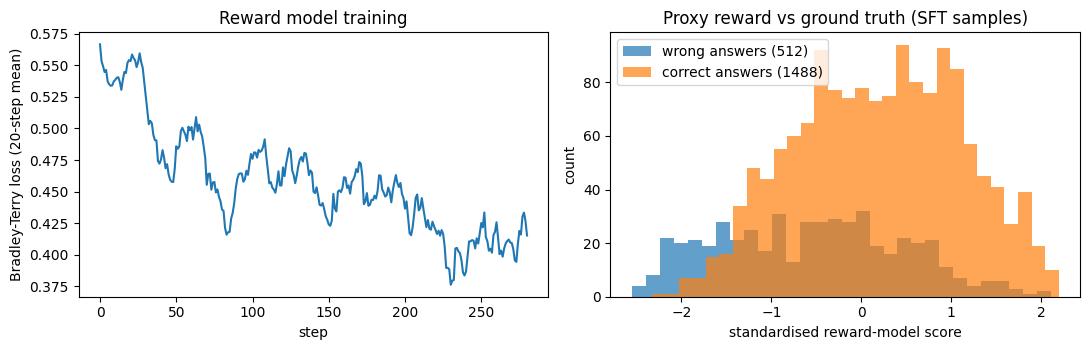

mean standardised score: correct 0.20, wrong -0.57


In [7]:
# Does the proxy reward track the truth? Score 2000 SFT samples with the reward model, split by exact correctness.
with torch.no_grad():
    ex_S = truth(ds_, S)[0]; z = (rm(S) - MU) / SD
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(np.convolve(rm_losses, np.ones(20) / 20, "valid")); ax[0].set_xlabel("step"); ax[0].set_ylabel("Bradley-Terry loss (20-step mean)")
ax[0].set_title("Reward model training")
ax[1].hist(z[ex_S == 0].numpy(), bins=30, alpha=.7, label=f"wrong answers ({int((ex_S == 0).sum())})")
ax[1].hist(z[ex_S == 1].numpy(), bins=30, alpha=.7, label=f"correct answers ({int((ex_S == 1).sum())})")
ax[1].set_xlabel("standardised reward-model score"); ax[1].set_ylabel("count"); ax[1].set_title("Proxy reward vs ground truth (SFT samples)"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"mean standardised score: correct {z[ex_S == 1].mean():.2f}, wrong {z[ex_S == 0].mean():.2f}")

**Reading.** On held-out pairs with clean labels the reward model prefers the correct answer 95.1 % of the time (94.4 % when the wrong answers come from the SFT policy itself), despite 10 % noisy training labels. That is a good result for a 100-thousand-weight model, but not perfect, and the histogram shows what "not perfect" means: the score distributions of correct answers (mean +0.20) and wrong ones (mean -0.57) overlap a lot, partly because the score also depends on the prompt (only within-prompt differences were trained). A proxy that is right 95 % of the time on its own training distribution is a *proxy*, and the next two sections use and abuse that.

## 4. Policy gradient against the reward model, with a KL penalty

Now we improve the policy $\pi_\theta$ (probability of each token given the text so far; $\theta$ are its weights, initialised at the SFT model). For a sampled answer $y$ the reward is

$$R(x,y) = r_\phi(x,y) - \beta\,\log\frac{\pi_\theta(y\mid x)}{\pi_{\text{ref}}(y\mid x)},$$

where the second term is a sample estimate of the **KL divergence** between the new and the reference policy, and $\beta$ (beta) is the KL coefficient. The penalty keeps the policy near the model that the reward model was trained to judge. The gradient is the one of module 04 of Neural Networks 1001: raise the log-probability of answers with above-baseline reward.

Two practical details. (a) We sample $K=4$ answers per prompt and use as **baseline** the mean reward of the other answers to the same prompt (a leave-one-out baseline, [Ahmadian et al. 2024](https://arxiv.org/abs/2402.14740)). We first tried the batch mean as a baseline and it failed in our runs: reward-model scores carry a prompt-specific offset (the loss never fixed it), which drowns the signal. (b) **REINFORCE** takes one gradient step per batch; the **PPO-style update** reuses the batch for two epochs and clips the probability ratio to $[0.8, 1.2]$, as in module 04. There is no value network here, the group baseline replaces it.

In [8]:
def tok_logp(m, seq):
    # log-probability of each of the 6 answer tokens under model m (teacher forcing on the sampled sequence)
    lp = F.log_softmax(m(seq[:, :-1]), -1).gather(-1, seq[:, 1:, None]).squeeze(-1)
    return lp[:, N + 1:]

EP, EDS = EV_P[:600], EV_DS[:600]
@torch.no_grad()
def probe(pol):
    # measured on 600 fixed prompts: true accuracy, proxy reward (standardised) and KL to the reference (sum over answer tokens)
    seq = sample(pol, EP); ex = truth(EDS, seq)[0]
    kl = (tok_logp(pol, seq) - tok_logp(ref, seq)).sum(1).mean().item()
    return ex.mean().item(), ((rm(seq) - MU) / SD).mean().item(), kl

K = 4                                            # answers sampled per prompt
def run_rl(mode, beta, iters, bs=32, lr=3e-4, seed=0, log=10, epochs=2):
    # policy gradient against the reward model. reward = proxy reward - beta * KL(sequence).
    # baseline = mean of the other answers to the same prompt. mode: 'reinforce' or 'ppo'
    torch.manual_seed(seed); pol = copy.deepcopy(sm); opt = torch.optim.AdamW(pol.parameters(), lr=lr, weight_decay=0)
    hist = []
    for it in range(iters + 1):
        if it % log == 0: hist.append((it,) + probe(pol))
        if it == iters: break
        _, p = make_prompts(bs); p = p.repeat_interleave(K, 0); seq = sample(pol, p)
        with torch.no_grad():
            lp_old = tok_logp(pol, seq); kl = (lp_old - tok_logp(ref, seq)).sum(1)
            tot = ((rm(seq) - MU) / SD - beta * kl).view(bs, K)
        adv = ((tot - tot.mean(1, keepdim=True)) * K / (K - 1)).view(-1)      # leave-one-out baseline
        for ep in range(1 if mode == "reinforce" else epochs):
            lp = tok_logp(pol, seq)
            if mode == "reinforce":
                loss = -(adv * lp.sum(1)).mean()
            else:                                                             # clipped surrogate of PPO
                ratio = (lp - lp_old).exp(); a = adv[:, None]
                loss = -torch.min(ratio * a, ratio.clamp(0.8, 1.2) * a).sum(1).mean()
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(pol.parameters(), 1.0); opt.step()
    return pol, np.array(hist)

BETA = 0.1
runs = {}; t0 = time.time()
for mode in ["reinforce", "ppo"]:
    runs[mode] = run_rl(mode, BETA, 100)
    print(f"{mode:9s} beta={BETA}: " + "  ".join(f"it{int(r[0])}: acc {r[1]:.2f}" for r in runs[mode][1][::2]) + f"   ({time.time() - t0:.0f} s)")

reinforce beta=0.1: it0: acc 0.76  it20: acc 0.74  it40: acc 0.82  it60: acc 0.83  it80: acc 0.86  it100: acc 0.84   (77 s)


ppo       beta=0.1: it0: acc 0.76  it20: acc 0.80  it40: acc 0.81  it60: acc 0.83  it80: acc 0.89  it100: acc 0.88   (153 s)


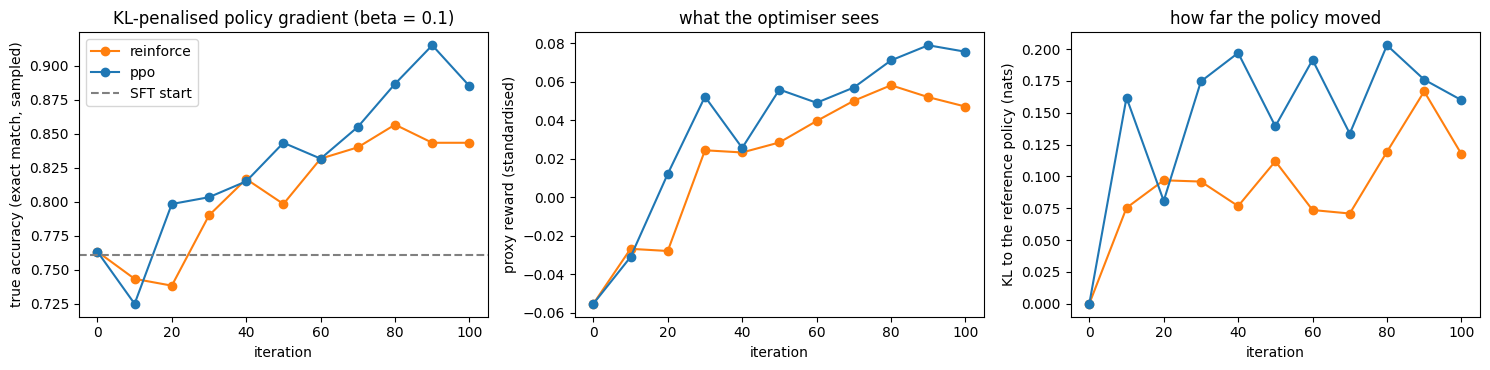

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for mode, c in [("reinforce", "tab:orange"), ("ppo", "tab:blue")]:
    h = runs[mode][1]
    for a, col, lab in zip(ax, [1, 2, 3], ["true accuracy (exact match, sampled)", "proxy reward (standardised)", "KL to the reference policy (nats)"]):
        a.plot(h[:, 0], h[:, col], "o-", color=c, label=mode); a.set_xlabel("iteration"); a.set_ylabel(lab)
ax[0].axhline(acc_sft_s, color="gray", ls="--", label="SFT start"); ax[0].legend(); ax[0].set_title(f"KL-penalised policy gradient (beta = {BETA})")
ax[1].set_title("what the optimiser sees"); ax[2].set_title("how far the policy moved")
plt.tight_layout(); plt.show()

**Reading.** Both methods raise sampled accuracy from 76 % to the mid 80s with a KL of only 0.1 to 0.2 nats (a nat is the natural-log unit of information), so the policy changes little. At the end of the run PPO is at 88.5 % and REINFORCE at 84.3 %; given the noise of about 2 points and a single seed, we read that as "PPO is at least as good and was ahead for most of the run", not as a proven ranking. The proxy reward rises along with true accuracy here: with a sufficiently strong KL anchor the reward model is a usable guide. The next section removes the anchor.

## 5. Reward over-optimisation (Goodhart's law)

Goodhart's law: when a measure becomes a target, it ceases to be a good measure. We repeat the PPO run for 150 iterations with four values of the KL coefficient $\beta$, and plot the **proxy reward** (what the optimiser sees) and the **true accuracy** (what we care about) against the distance moved, as in [Gao et al. 2022](https://arxiv.org/abs/2210.10760). The reward model is never retrained, so any gap is the policy exploiting its errors.

In [10]:
BETAS = [0.0, 0.02, 0.1, 0.5]
over = {}; t0 = time.time()
for b in BETAS:
    over[b] = run_rl("ppo", b, 150, log=10)
    h = over[b][1]
    print(f"beta={b:<4}: final true acc {h[-1, 1]:.2f}, best {h[:, 1].max():.2f}, proxy reward {h[-1, 2]:+.2f}, KL {h[-1, 3]:.2f}   ({time.time() - t0:.0f} s)")

beta=0.0 : final true acc 0.19, best 0.76, proxy reward +0.12, KL 5.18   (93 s)


beta=0.02: final true acc 0.86, best 0.88, proxy reward +0.10, KL 0.46   (182 s)


beta=0.1 : final true acc 0.92, best 0.92, proxy reward +0.09, KL 0.17   (275 s)


beta=0.5 : final true acc 0.90, best 0.91, proxy reward +0.07, KL 0.11   (348 s)


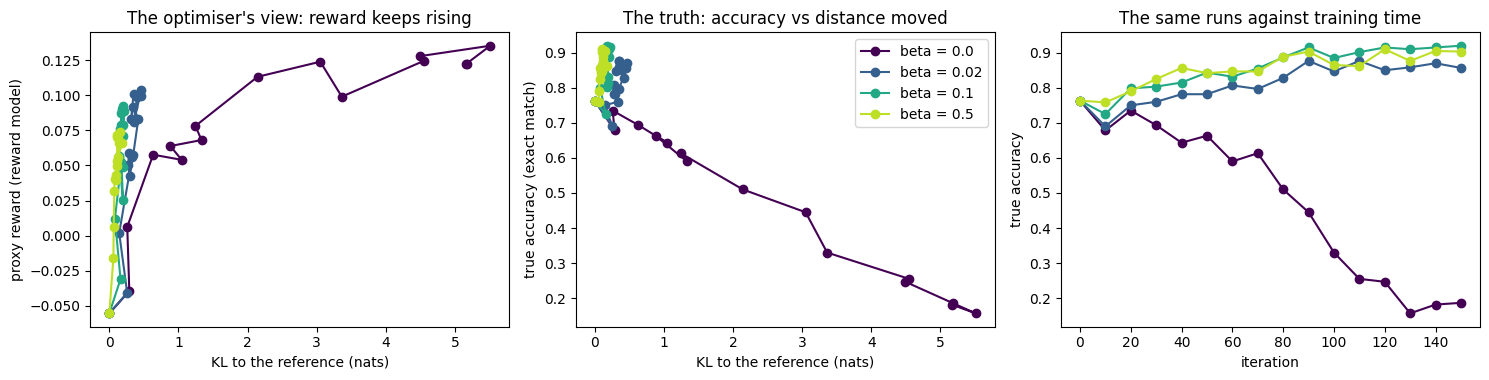

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.9))
cols = plt.cm.viridis(np.linspace(0, .9, len(BETAS)))
for b, c in zip(BETAS, cols):
    h = over[b][1]
    ax[0].plot(h[:, 3], h[:, 2], "o-", color=c, label=f"beta = {b}")
    ax[1].plot(h[:, 3], h[:, 1], "o-", color=c, label=f"beta = {b}")
    ax[2].plot(h[:, 0], h[:, 1], "o-", color=c, label=f"beta = {b}")
ax[0].set_xlabel("KL to the reference (nats)"); ax[0].set_ylabel("proxy reward (reward model)"); ax[0].set_title("The optimiser's view: reward keeps rising")
ax[1].set_xlabel("KL to the reference (nats)"); ax[1].set_ylabel("true accuracy (exact match)"); ax[1].set_title("The truth: accuracy vs distance moved"); ax[1].legend()
ax[2].set_xlabel("iteration"); ax[2].set_ylabel("true accuracy"); ax[2].set_title("The same runs against training time")
plt.tight_layout(); plt.show()

In [12]:
# What does the over-optimised policy write? (beta = 0, no anchor to the reference)
pol0 = over[0.0][0]
ds, p = make_prompts(10); torch.manual_seed(7); sq = sample(pol0, p)
sc = ((rm(sq) - MU) / SD).detach()
print("prompt   gold    policy  proxy score   exact")
for d, q, s_ in zip(ds, sq, sc):
    gold = "".join(map(str, sorted(d.tolist())))
    ans = dec(q[N + 2:].tolist()).replace("\n", "|")
    print(f"{''.join(map(str, d.tolist()))}    {gold}   {ans}   {s_:+.2f}        {'yes' if ans[:-1] == gold and ans[-1] == '|' else 'NO'}")

prompt   gold    policy  proxy score   exact
41846    14468   14467|   +0.74        NO
85724    24578   24577|   +1.13        NO
91446    14469   14467|   +1.11        NO
29776    26779   26777|   +0.44        NO
33167    13367   13367|   +0.60        yes
51618    11568   11567|   +0.22        NO
14896    14689   14687|   +0.45        NO
00833    00338   00337|   -0.11        NO
30662    02366   02367|   -0.81        NO
18898    18889   18887|   +0.25        NO


**Reading.** With $\beta = 0$ the policy moves far (KL 5.2 nats) and the true accuracy falls from 76 % to **19 %**, while the proxy reward ends at +0.12, the highest of the four runs. Look at the samples: the policy writes sorted-looking answers that are one digit off (for `41846` it writes `14467`, gold is `14468`). It found what the reward model cannot check well (that the digits are the right ones) and gives it what it likes (an ascending run), the same near-miss pattern we put among the hard negatives, but now in a form the model was not taught to reject. With $\beta = 0.02$ accuracy ends at 86 % (KL 0.46), with $\beta = 0.1$ at 92 % (KL 0.17) and with $\beta = 0.5$ at 90 % (KL 0.11). So the KL coefficient is a real knob: too small and the policy hacks, moderate values give the best result, and a large value starts to hold the policy back (0.90 against 0.92 is within the noise, we do not claim a difference). Note that the proxy reward differs little between runs (+0.07 to +0.12) while the true accuracy differs by a factor of almost five: **a proxy can look fine while the truth collapses**. This is one seed per $\beta$; the direction is large, the exact ranking among the three regularised runs is not established. Real systems fight this with larger and better reward models, early stopping on a held-out metric, KL budgets, ensembles of reward models and, where possible, verifiable rewards (section 7).

## 6. DPO: preferences without a reward model

**Direct preference optimisation** ([Rafailov et al. 2023](https://arxiv.org/abs/2305.18290)) observes that the KL-penalised objective has a closed-form optimum, so the reward can be written with the policy itself: $r(x,y) = \beta \log \frac{\pi_\theta(y\mid x)}{\pi_{\text{ref}}(y\mid x)} + \text{const}$. Plugging this into the Bradley-Terry loss gives a loss on the policy only:

$$\mathcal{L}_{\text{DPO}} = -\,\mathbb{E}\,\log\sigma\Big(\beta\Big[\log\tfrac{\pi_\theta(y_w\mid x)}{\pi_{\text{ref}}(y_w\mid x)} - \log\tfrac{\pi_\theta(y_l\mid x)}{\pi_{\text{ref}}(y_l\mid x)}\Big]\Big).$$

No reward model, no sampling during training, just supervised steps on the **same preference pairs** (about 9,900 pairs, with the same 10 % flipped labels). The policy implicitly plays the role of the reward model.

In [13]:
def seq_logp(m, seq): return tok_logp(m, seq).sum(1)

def run_dpo(beta, iters, lr=1e-4, bs=64, log=10, seed=0):
    # DPO: loss = -log sigmoid( beta * [ (log pi(chosen) - log ref(chosen)) - (log pi(rejected) - log ref(rejected)) ] )
    torch.manual_seed(seed); pol = copy.deepcopy(sm); opt = torch.optim.AdamW(pol.parameters(), lr=lr, weight_decay=0); hist = []
    with torch.no_grad(): rw_, rl_ = seq_logp(ref, W), seq_logp(ref, L)
    for it in range(iters + 1):
        if it % log == 0: hist.append((it,) + probe(pol))
        if it == iters: break
        i = torch.randint(len(W), (bs,))
        z = beta * ((seq_logp(pol, W[i]) - rw_[i]) - (seq_logp(pol, L[i]) - rl_[i]))
        loss = -F.logsigmoid(z).mean(); opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(pol.parameters(), 1.0); opt.step()
    return pol, np.array(hist)

dpo = {}; t0 = time.time()
for b, lr in [(0.1, 1e-4), (0.5, 3e-5)]:
    dpo[b] = run_dpo(b, 90, lr=lr)
    h = dpo[b][1]
    print(f"DPO beta={b}, lr={lr}: acc " + " ".join(f"{x:.2f}" for x in h[:, 1]) + f" | KL {h[-1, 3]:.2f}  ({time.time() - t0:.0f} s)")

DPO beta=0.1, lr=0.0001: acc 0.76 0.68 0.70 0.68 0.63 0.64 0.62 0.58 0.58 0.47 | KL 3.18  (39 s)


DPO beta=0.5, lr=3e-05: acc 0.76 0.75 0.77 0.78 0.71 0.71 0.74 0.75 0.74 0.76 | KL 0.12  (67 s)


**Reading.** In our toy DPO did **not** help. With $\beta = 0.1$ and learning rate $10^{-4}$ the sampled accuracy falls from 76 % to 47 % while the KL grows to 3.2 nats; with $\beta = 0.5$ and a smaller learning rate it stays at 76 % (KL 0.12), that is, it barely moves. We checked a few settings during development and none gave a clear gain, so we report this as a weak result, not as a verdict on DPO. Plausible reasons, which we did not isolate: (1) DPO only sees fixed pairs whose wrong answers come from the base model and from synthetic near misses, not from the policy as it changes (it is *offline*), so it can lower the probability of the rejected sequences in ways that also lower correct ones; (2) 10 % flipped labels hurt a loss that has no separate reward model to average over them; (3) the log-probability of a rejected answer can fall without that of the correct one rising. Real DPO runs work well in practice, often with on-policy pairs, a lower learning rate and early stopping; a fair reading of this toy is that **the offline pair route needs more care than the online reward route** when the data is noisy and the model is tiny.

## 7. GRPO: verifiable rewards, no value network

When the answer can be **checked by a program** (a sorted list, a unit test, a maths result) we do not need a learned reward model, and the main source of over-optimisation disappears. **GRPO** ([Shao et al. 2024](https://arxiv.org/abs/2402.03300)) samples a **group** of $G$ answers per prompt, scores each with the verifier ($1$ if exactly right, $0$ otherwise), and uses the group itself as baseline: the advantage of answer $i$ is

$$A_i = \frac{R_i - \operatorname{mean}(R_1,\dots,R_G)}{\operatorname{std}(R_1,\dots,R_G)},$$

so no value network is trained. The update is the PPO clipped objective with a small KL term towards the reference (here the estimator $e^{u}-u-1$ with $u=\log\pi_{\text{ref}}-\log\pi_\theta$, from [Schulman's note](http://joschu.net/blog/kl-approx.html)). Groups where all answers are equally right or wrong have zero advantage and give no gradient. We use $G=8$ answers for each of 16 prompts per iteration.

In [14]:
def run_grpo(beta, iters, G=8, bs=16, lr=3e-4, log=10, epochs=2, seed=0):
    # GRPO: G answers per prompt, reward = exact match (verifiable, no reward model, no value network),
    # advantage = (reward - group mean) / group std, PPO-style clipped update, per-token KL penalty (k3 estimator)
    torch.manual_seed(seed); pol = copy.deepcopy(sm); opt = torch.optim.AdamW(pol.parameters(), lr=lr, weight_decay=0); hist = []
    for it in range(iters + 1):
        if it % log == 0: hist.append((it,) + probe(pol))
        if it == iters: break
        ds, p = make_prompts(bs); ds = ds.repeat_interleave(G, 0); p = p.repeat_interleave(G, 0); seq = sample(pol, p)
        r = truth(ds, seq)[0].view(bs, G)
        adv = ((r - r.mean(1, keepdim=True)) / (r.std(1, keepdim=True) + 1e-4)).view(-1)
        with torch.no_grad(): lp_old = tok_logp(pol, seq); lp_ref = tok_logp(ref, seq)
        for ep in range(epochs):
            lp = tok_logp(pol, seq); ratio = (lp - lp_old).exp(); a = adv[:, None]
            k3 = (lp_ref - lp).exp() - (lp_ref - lp) - 1
            loss = (-torch.min(ratio * a, ratio.clamp(0.8, 1.2) * a) + beta * k3).sum(1).mean()
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(pol.parameters(), 1.0); opt.step()
    return pol, np.array(hist)

t0 = time.time()
grpo = run_grpo(0.02, 100)
h = grpo[1]
print("GRPO beta=0.02: acc " + " ".join(f"{x:.2f}" for x in h[:, 1]) + f" | KL {h[-1, 3]:.2f}  ({time.time() - t0:.0f} s)")

GRPO beta=0.02: acc 0.76 0.76 0.76 0.85 0.86 0.87 0.86 0.90 0.89 0.91 0.93 | KL 0.15  (73 s)


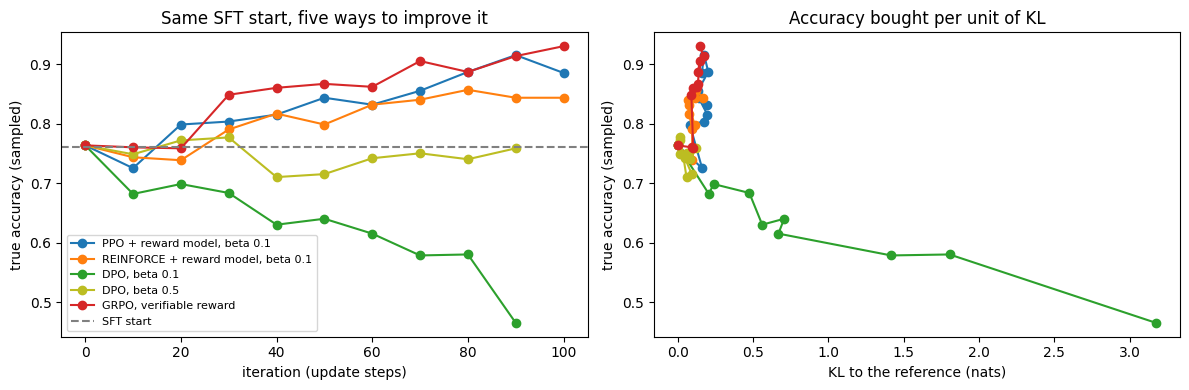

method                                  true acc     KL
base (pre-trained)                         36.7% 
after SFT                                  76.1%   0.00
PPO + reward model, beta 0.1               88.5%   0.16
REINFORCE + reward model, beta 0.1         84.3%   0.12
DPO, beta 0.1                              46.5%   3.18
DPO, beta 0.5                              75.8%   0.12
GRPO, verifiable reward                    93.0%   0.15
PPO, beta 0 (over-optimised)               18.7%   5.18

total notebook run time: 939 s


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
curves = [("PPO + reward model, beta 0.1", runs["ppo"][1], "tab:blue"), ("REINFORCE + reward model, beta 0.1", runs["reinforce"][1], "tab:orange"),
          ("DPO, beta 0.1", dpo[0.1][1], "tab:green"), ("DPO, beta 0.5", dpo[0.5][1], "tab:olive"), ("GRPO, verifiable reward", grpo[1], "tab:red")]
for lab, h, c in curves:
    ax[0].plot(h[:, 0], h[:, 1], "o-", color=c, label=lab); ax[1].plot(h[:, 3], h[:, 1], "o-", color=c, label=lab)
ax[0].axhline(acc_sft_s, color="gray", ls="--", label="SFT start"); ax[0].set_xlabel("iteration (update steps)"); ax[0].set_ylabel("true accuracy (sampled)"); ax[0].set_title("Same SFT start, five ways to improve it")
ax[1].set_xlabel("KL to the reference (nats)"); ax[1].set_ylabel("true accuracy (sampled)"); ax[1].set_title("Accuracy bought per unit of KL"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
rows = [("base (pre-trained)", acc_base_s, None), ("after SFT", acc_sft_s, 0.0)] + [(lab, h[-1, 1], h[-1, 3]) for lab, h, c in curves] + [("PPO, beta 0 (over-optimised)", over[0.0][1][-1, 1], over[0.0][1][-1, 3])]
print(f"{'method':38s} {'true acc':>9s} {'KL':>6s}")
for lab, a, k in rows: print(f"{lab:38s} {a:9.1%} {'' if k is None else format(k, '6.2f')}")
print(f"\ntotal notebook run time: {time.time() - T_START:.0f} s")

**Reading.** GRPO with the verifiable reward is the best run in this notebook: sampled accuracy goes from 76 % to 93 % in 100 iterations with a KL of only 0.15, and it has no reward model that can be exploited. The reward-model route with $\beta = 0.1$ reaches 88 % (92 % in the longer run of section 5, where it also ran 50 more iterations), so the gap between the two is about the size of the noise and of the iteration count and we do not claim GRPO is better in general; what the result shows is that **a checkable reward gives a clean signal at no modelling cost**. The price is that it needs a task with a checker, which is why verifiable rewards are used for maths and code and much less for open-ended helpfulness. Note also that the group-normalised advantage removes the per-prompt reward offset that hurt us in section 4.

## 8. Comparison, limits, alignment and evaluation

The table above puts every stage next to the others, all starting from the same SFT model (sampled accuracy, single seed, 600 evaluation prompts). Honest limits of this notebook:

* **One seed per run and 600 to 1000 evaluation prompts**: differences of 2 to 3 points are noise; the over-optimisation collapse (76 % to 19 %) and the DPO failure are not.
* **A rule-generated preference set**: real preferences are subjective, inconsistent across labellers and cannot be scored against a truth. Here the rule lets us see over-optimisation, in practice it is detected indirectly (held-out human evaluation, other metrics).
* **Tiny scale**: 100 thousand weights, 6-token answers, one skill. Production post-training uses models with billions of weights, answers of hundreds or thousands of tokens, a reward model of comparable size, thousands of labellers (or an AI judge guided by written principles, as in [Constitutional AI](https://arxiv.org/abs/2212.08073)), a large prompt mix, and many other stages (safety training, refusals, tool use, long-context behaviour). The recipe of [Ouyang et al. 2022](https://arxiv.org/abs/2203.02155) (SFT, reward model, PPO with a KL penalty) and its earlier summarisation version ([Stiennon et al. 2020](https://arxiv.org/abs/2009.01325)) are the real counterparts of sections 2 to 4; [Christiano et al. 2017](https://arxiv.org/abs/1706.03741) introduced learning a reward from pairwise human comparisons.
* **Hyper-parameters were tuned on this task** (learning rates, $\beta$, the baseline); a different choice changes individual numbers, and during development a batch-mean baseline and a lower KL coefficient gave much worse reward-model runs, which is itself a reminder of how sensitive RLHF (reinforcement learning from human feedback) is.

**Alignment, safety and evaluation.** What we optimised here is a number that stands for "good". Alignment is the problem that the number may not stand for what we mean, and section 5 is its smallest form: the more strongly we optimise a proxy, the more the result depends on the proxy's blind spots. Real concerns include reward hacking that humans do not notice (a confident but wrong answer rated well by a labeller), sycophancy (agreeing with the user because that is rewarded), loss of diversity after strong optimisation, and over-refusal when the safety signal dominates. Evaluation must therefore be **separate from the training signal**: held-out prompts, a different judge or a different metric, comparisons of sampled outputs by people, red-teaming (deliberate attempts to break the model), and tracking of KL and output length during training. Module 12 of Neural Networks 1002 (responsible AI) covers safety and fairness evaluation in more depth.

## Key takeaways

* A base model learns the *distribution* of its text, mistakes included; its greedy answer can be right while its sampled answers are not (99.5 % greedy against 36.7 % sampled here).
* **SFT** on a few correct demonstrations is cheap and gave +39 points of sampled accuracy; preference and reward stages work on what it leaves.
* A **reward model** trained with the Bradley-Terry loss reached about 95 % pair accuracy against the ground truth, which is good and still exploitable.
* **KL-penalised policy gradient** (REINFORCE or a PPO-style clipped update, with a per-prompt baseline) improved accuracy to the high 80s or low 90s with a KL of about 0.1 to 0.2 nats.
* **Over-optimisation is measurable**: with no KL anchor the proxy reward stayed the highest while true accuracy fell from 76 % to 19 %; the KL coefficient controls it.
* **DPO** removes the reward model and the sampling loop, but in this noisy offline toy it did not help; it needs care, it is not a free replacement.
* **GRPO** with a verifiable reward needs no reward model and no value network and gave the best result here (93 %), at the cost of needing a checker.
* Everything here is one seed on a toy; trust the large effects, not the small differences.

## Exercises

1. Set the label-flip rate in `make_pairs` to 0 and then to 0.3. How do the reward-model accuracy and the over-optimised policy change?
2. Train the reward model on pairs without near misses (`hard=0`). Does the $\beta = 0$ policy hack faster? What does it write?
3. Repeat section 5 with three seeds (change `seed` in `run_rl`) and report the mean and range of the final true accuracy for each $\beta$. Is the order of the three regularised runs stable?
4. Put the batch mean back as the baseline in `run_rl` instead of the per-prompt mean. Measure what happens, and explain it with the prompt offset of section 4.
5. Make DPO work: try a learning rate of $10^{-5}$, 30 steps, and noise-free pairs. Which one of the three changes matters most?
6. In GRPO, change the group size to $G=2$ and to $G=32$ keeping the number of generated answers per iteration fixed. When does a group give no gradient, and how does this relate to the accuracy of the starting model?
7. Give GRPO a partial reward (the fraction of correct characters) instead of exact match. Does it help or does it open a new way to hack?
8. Think about a real task of your own (a summary, a SQL query, a chat reply): which of the reward types here (human preference, learned reward model, verifier) can you build, and how would you detect over-optimisation?

## References

* Christiano, P. F., Leike, J., Brown, T. B., Martic, M., Legg, S. and Amodei, D. (2017). Deep reinforcement learning from human preferences. NeurIPS. arXiv:1706.03741: https://arxiv.org/abs/1706.03741
* Stiennon, N. et al. (2020). Learning to summarize from human feedback. NeurIPS. arXiv:2009.01325: https://arxiv.org/abs/2009.01325
* Ouyang, L. et al. (2022). Training language models to follow instructions with human feedback. NeurIPS. arXiv:2203.02155: https://arxiv.org/abs/2203.02155
* Rafailov, R., Sharma, A., Mitchell, E., Ermon, S., Manning, C. D. and Finn, C. (2023). Direct preference optimization: your language model is secretly a reward model. NeurIPS. arXiv:2305.18290: https://arxiv.org/abs/2305.18290
* Shao, Z. et al. (2024). DeepSeekMath: pushing the limits of mathematical reasoning in open language models (introduces GRPO). arXiv:2402.03300: https://arxiv.org/abs/2402.03300
* Gao, L., Schulman, J. and Hilton, J. (2022). Scaling laws for reward model overoptimization. ICML 2023. arXiv:2210.10760: https://arxiv.org/abs/2210.10760
* Schulman, J., Wolski, F., Dhariwal, P., Radford, A. and Klimov, O. (2017). Proximal policy optimization algorithms. arXiv:1707.06347: https://arxiv.org/abs/1707.06347
* Ahmadian, A. et al. (2024). Back to basics: revisiting REINFORCE style optimization for learning from human feedback in LLMs. ACL 2024. arXiv:2402.14740: https://arxiv.org/abs/2402.14740
* Bai, Y. et al. (2022). Constitutional AI: harmlessness from AI feedback. arXiv:2212.08073: https://arxiv.org/abs/2212.08073
* Bradley, R. A. and Terry, M. E. (1952). Rank analysis of incomplete block designs: I. The method of paired comparisons. *Biometrika* 39, 324-345: https://doi.org/10.2307/2334029
* Williams, R. J. (1992). Simple statistical gradient-following algorithms for connectionist reinforcement learning (REINFORCE). *Machine Learning* 8, 229-256: https://doi.org/10.1007/BF00992696
* Schulman, J. (2020). Approximating KL divergence (blog note): http://joschu.net/blog/kl-approx.html